In [2]:
import matplotlib.pyplot as plt
import numpy as np

# Q1
The goal of this exercise is to continue exploring the LLN. In
particular, you will gain deeper insight into why sample means
have less variability than individual samples.

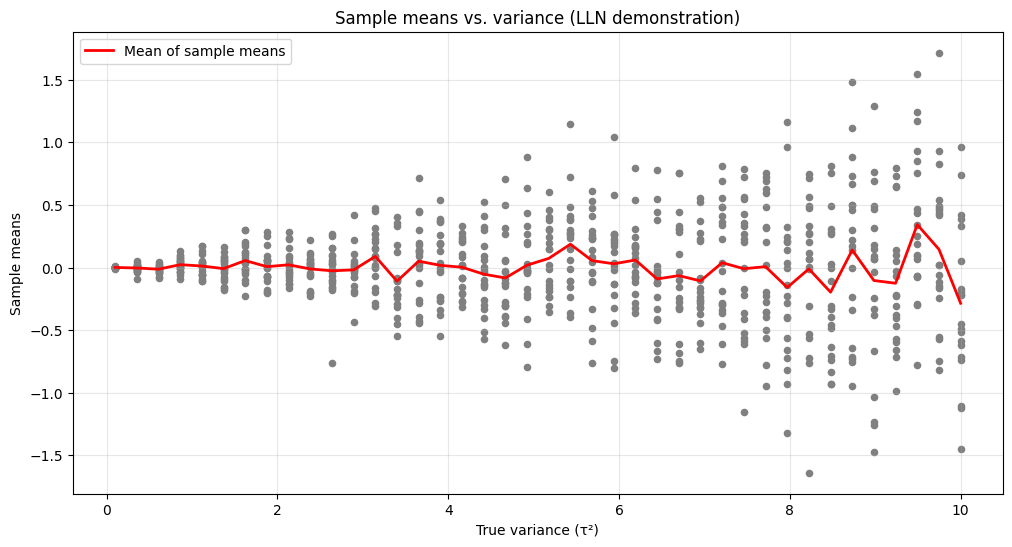

In [4]:
var_values = np.linspace(0.1, 10, 40)

N = 20
sample_means = np.zeros((len(var_values), N))
sample_vars = np.zeros((len(var_values), N))

for i, v in enumerate(var_values):
    for j in range(20):
        sample = np.random.normal(loc=0, scale=v, size=200)
        sample_means[i, j] = np.mean(sample)
        sample_vars[i, j] = np.var(sample, ddof=1)

# --- mean of sample means for each τ² ---
mean_of_means = np.mean(sample_means, axis=1)

plt.figure(figsize=(12, 6))

# scatter all 20 sample-means for each variance
for i in range(len(var_values)):
    plt.scatter(
        np.full(N, var_values[i]),  # x-values repeated N times
        sample_means[i, :],
        color='gray', s=20
    )

plt.plot(var_values, mean_of_means, color='red', linewidth=2, label='Mean of sample means')

plt.xlabel("True variance (τ²)")
plt.ylabel("Sample means")
plt.title("Sample means vs. variance (LLN demonstration)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

- "Not surprisingly, the sample means
become more variable as the within-sample variance (τ 2 ) in-
creases."

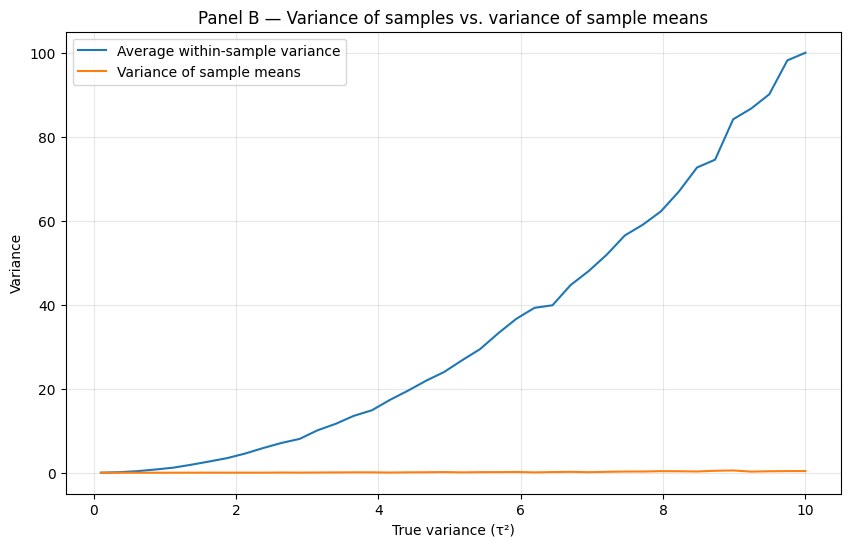

In [5]:
mean_of_vars = np.mean(sample_vars, axis=1)
var_of_means = np.var(sample_means, axis=1, ddof=1)

plt.figure(figsize=(10, 6))

plt.plot(var_values, mean_of_vars, label='Average within-sample variance')

plt.plot(var_values, var_of_means, label='Variance of sample means')

plt.xlabel("True variance (τ²)")
plt.ylabel("Variance")
plt.title("Panel B — Variance of samples vs. variance of sample means")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

- "although the data vari-
ability increases, the sample means are stably clustered around
the population mean."

# Q2


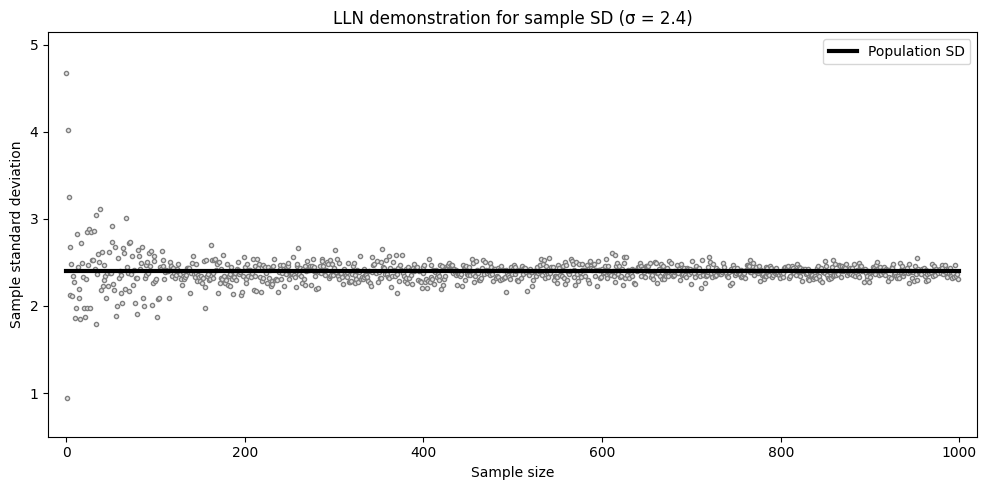

In [11]:
# 1. Create a large "population" ~ N(0, 2.4^2)
pop_sigma = 2.4
population = np.random.normal(loc=0, scale=pop_sigma, size=500000)

true_sigma = np.std(population)  # empirical population SD

# 2. LLN experiment
k = 1000
sampleSD = np.zeros(k)

for n in range(2, k + 1):
    sample = np.random.choice(population, size=n, replace=False)
    sampleSD[n - 2] = np.std(sample, ddof=1)

# 3. Plot
plt.figure(figsize=(10, 5))

plt.plot(sampleSD, 'o', markersize=3,
         markerfacecolor=(0.9, 0.9, 0.9),
         markeredgecolor=(0.5, 0.5, 0.5))

plt.plot([0, k], [true_sigma, true_sigma], 'k-', linewidth=3,
         label="Population SD")

plt.xlabel("Sample size")
plt.ylabel("Sample standard deviation")
plt.title("LLN demonstration for sample SD (σ = 2.4)")
plt.xlim([-20, k + 20])
plt.ylim([0.5, max(sampleSD) * 1.1])
plt.legend()

plt.tight_layout()
plt.show()

- "The key take-home message here is
that the LLN is formally defined for means, but the concept
holds for other descriptive statistics."

# Q3
Instead of com-
puting the characteristics of one sample, compute the mean
difference between two samples that are drawn from separate
distributions.

pop diff: -0.216
sam diff: -0.086


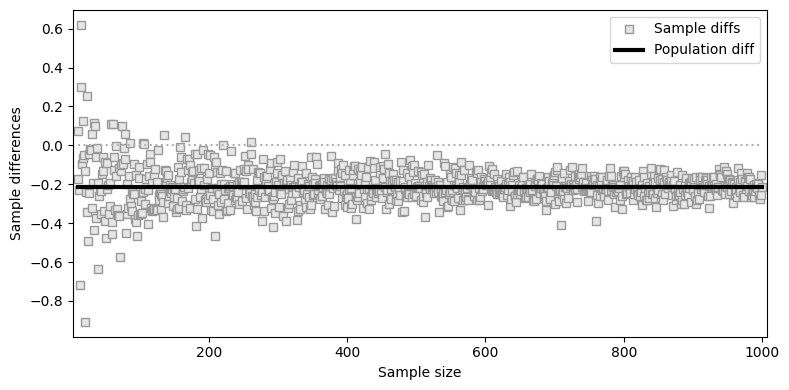

In [12]:
N = 10000
pop1 = np.random.normal(loc=3, size=N)
pop2 = np.random.normal(loc=3.2, size=N)

s1 = np.random.choice(pop1, size=30, replace=False)
s2 = np.random.choice(pop2, size=30, replace=False)

sam_diff = np.mean(s1) - np.mean(s2)
pop_diff = np.mean(pop1) - np.mean(pop2)

print(f"pop diff: {pop_diff:.3f}")
print(f"sam diff: {sam_diff:.3f}")

k = 1000
sam_sizes = np.arange(10, 1001)
sam_diffs = np.zeros(len(sam_sizes))

for i, n in enumerate(sam_sizes):
    s1 = np.random.choice(pop1, size=n, replace=False)
    s2 = np.random.choice(pop2, size=n, replace=False)
    sam_diffs[i] = np.mean(s1) - np.mean(s2)

plt.figure(figsize=(8, 4))

plt.plot(sam_sizes, sam_diffs, 's',
         markerfacecolor=(.9, .9, .9),
         color=(.6, .6, .6))

# horizontal line: population difference
plt.plot(sam_sizes[[0, -1]],
         [pop_diff, pop_diff],
         'k', linewidth=3)

# horizontal zero line
plt.plot(sam_sizes[[0, -1]],
         [0, 0],
         color=(.7, .7, .7),
         linestyle=':')

plt.xlabel('Sample size')
plt.ylabel('Sample differences')
plt.xlim([sam_sizes[0] - 7, sam_sizes[-1] + 7])
plt.legend(('Sample diffs', 'Population diff'))
plt.tight_layout()

plt.show()

- "Observations: Between-sample characteristics are subject to
the same variability as within-sample characteristics, even with
relatively large sample sizes. That’s probably not surprising,
but empirical demonstrations help build lasting intuition."
- "But there is a more striking — dare I write startling? —
observation: Many random samples with sample sizes below
∼200 actually showed the opposite direction as the population
difference (note the dotted gray line at y=0).
By the way, there is nothing special about a sample size of
200; it depends on the magnitude of the population mean dif-
ference and the variabilities."

# Q4

51.0


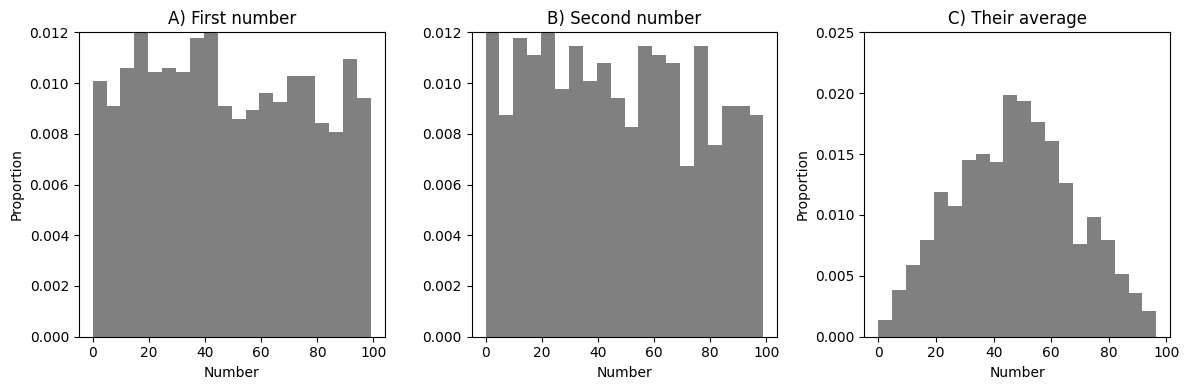

In [17]:
a = np.random.randint(low=0, high=100)
b = np.random.randint(low=0, high=100)
print((a + b) / 2)

a = np.zeros((1200,))
b = np.zeros((1200,))
avg = np.zeros((1200,))

for i in range(1200):
    a[i] = np.random.randint(low=0, high=100)
    b[i] = np.random.randint(low=0, high=100)
    avg[i] = (a[i] + b[i]) / 2

plt.figure(figsize=(12, 4))

# Panel A
plt.subplot(1, 3, 1)
plt.hist(a, bins=20, density=True, color="gray")
plt.title("A) First number")
plt.xlabel("Number")
plt.ylabel("Proportion")
plt.ylim(0, 0.012)

# Panel B
plt.subplot(1, 3, 2)
plt.hist(b, bins=20, density=True, color="gray")
plt.title("B) Second number")
plt.xlabel("Number")
plt.ylim(0, 0.012)

# Panel C
plt.subplot(1, 3, 3)
plt.hist(avg, bins=20, density=True, color="gray")
plt.title("C) Their average")
plt.xlabel("Number")
plt.ylabel("Proportion")
plt.ylim(0, 0.025)

plt.tight_layout()
plt.show()

- "The point here is that we took two things in the universe
that are non-Gaussian distributed, mixed them together, and
the distribution of that mixture is more Gaussian than either
original distribution."

# Q5
The CLT works only when the samples are "big enough." That
should make sense at the extreme low end: If your sample
size is N = 1, then the "average" is just the sampled number,
and the sampling distribution will take the same shape as the
population distribution. But how big is "big enough"?

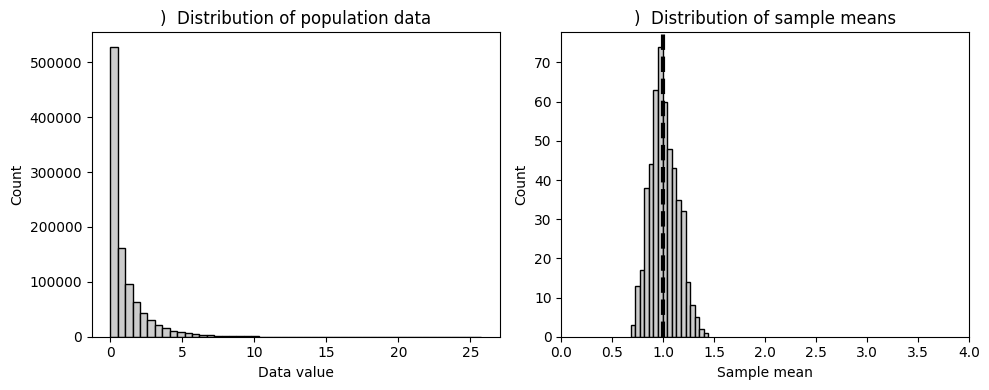

In [22]:
# new population!
Npop = 1000000
population = np.random.randn(Npop) ** 2

# parameters and initializations
samplesize = 100
numberOfExps = 500
samplemeans = np.zeros(numberOfExps)

# run the experiment!
for expi in range(numberOfExps):
    # compute and store its mean
    samplemeans[expi] = np.mean(np.random.choice(population, size=samplesize))

# show the results
fig, axs = plt.subplots(1, 2, figsize=(10, 4))

# histogram of the data
axs[0].hist(population, bins=50, color=[.8, .8, .8], edgecolor='k')
axs[0].set(xlabel='Data value', ylabel='Count')
axs[0].set_title(r')  Distribution of population data')
axs[0].ticklabel_format(style='plain')

# histogram of the sample means
axs[1].hist(samplemeans, bins='fd', color=[.8, .8, .8], edgecolor='k')
axs[1].set(xlabel='Sample mean', ylabel='Count', xlim=[0, 4])
axs[1].axvline(np.mean(population), linewidth=3, color='k', linestyle='--')
axs[1].set_title(r')  Distribution of sample means')

plt.tight_layout()
plt.show()

# Q6
The CLT also prescribes that the distribution of sample means
gets narrower with more samples. The purpose
of this exercise is to empirically confirm this by computing the
width of sample mean distributions as a function of sample
size.

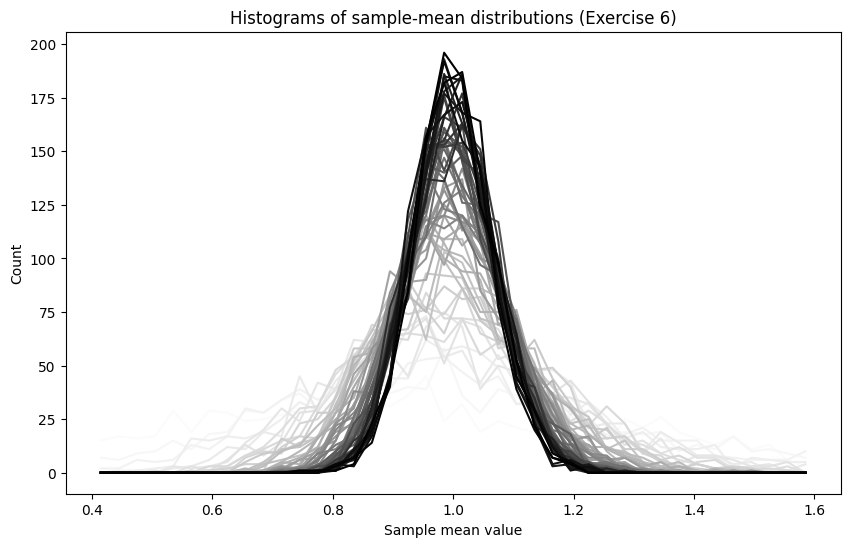

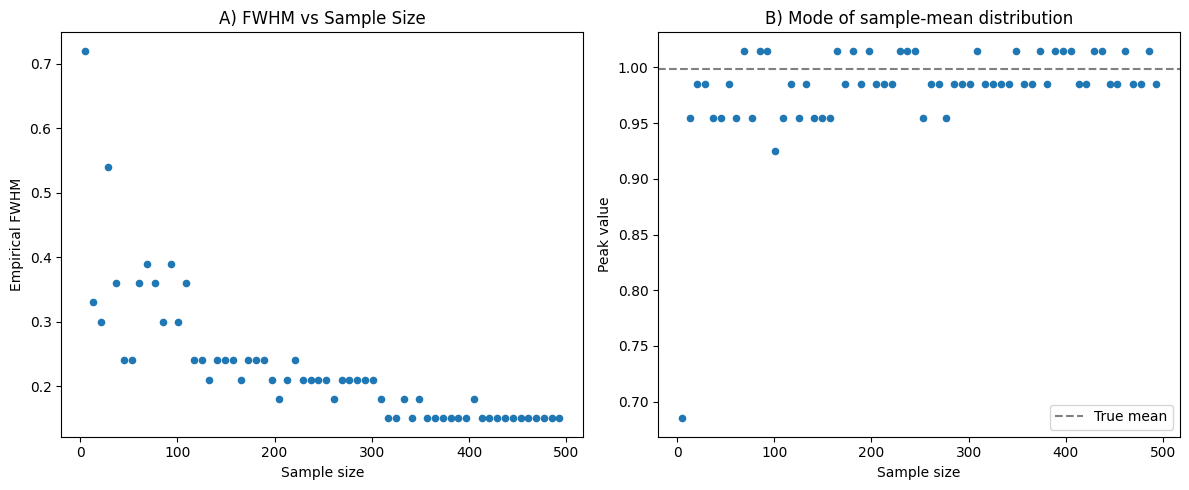

In [26]:
def empFWHM(x, y):
    # normalize
    y_tilde = (y - np.min(y)) / (np.max(y) - np.min(y))
    # find the peak
    idx_peak = np.argmax(y_tilde)
    # find the pre-peak half-maximum point
    pre_hm_idx = np.argmin(np.abs(y_tilde[:idx_peak + 1] - 0.5))
    # find the post-peak half-maximum point
    post_hm_idx = np.argmin(np.abs(y_tilde[idx_peak:] - 0.5)) + idx_peak
    fwhm = x[post_hm_idx] - x[pre_hm_idx]
    return fwhm, x[post_hm_idx], x[pre_hm_idx]


sample_sizes = np.arange(5, 501, 8)
x = np.random.normal(size=N) ** 2

FWHMs = []
peaks = []

# bins for ALL histograms
bins = np.linspace(0.4, 1.6, 41)
bin_centers = (bins[:-1] + bins[1:]) / 2

plt.figure(figsize=(10, 6))

for n in sample_sizes:

    # Generate 1000 sample means
    sample_means = np.zeros(1000)
    for i in range(1000):
        s = np.random.choice(x, size=n)
        sample_means[i] = np.mean(s)

    # Histogram
    yy, xx = np.histogram(sample_means, bins=bins)

    # Scale for grayscale intensity (larger n: darker)
    intensity = (n - sample_sizes.min()) / (sample_sizes.max() - sample_sizes.min())

    plt.plot(bin_centers, yy, color=str(1 - intensity))

    # Compute FWHM
    fwhm, right, left = empFWHM(bin_centers, yy)
    FWHMs.append(fwhm)

    # Peak = x value at highest bin
    peaks.append(bin_centers[np.argmax(yy)])

plt.xlabel("Sample mean value")
plt.ylabel("Count")
plt.title("Histograms of sample-mean distributions (Exercise 6)")
plt.show()

plt.figure(figsize=(12, 5))

# Panel A: FWHM vs sample size
plt.subplot(1, 2, 1)
plt.scatter(sample_sizes, FWHMs, s=20)
plt.xlabel("Sample size")
plt.ylabel("Empirical FWHM")
plt.title("A) FWHM vs Sample Size")

# Panel B: Peak location vs sample size
plt.subplot(1, 2, 2)
plt.scatter(sample_sizes, peaks, s=20)
plt.axhline(np.mean(x), color='gray', linestyle='--', label='True mean')
plt.xlabel("Sample size")
plt.ylabel("Peak value")
plt.title("B) Mode of sample-mean distribution")
plt.legend()

plt.tight_layout()
plt.show()

- "The conclusion is that, while increasing
the sample size makes the sample means distribution tighter,
it has little impact on the average of the sample mean distri-
butions."
1. Even when the population distribution is highly non-normal (e.g., χ²-like), the distribution of sample means becomes approximately normal.
2. As sample size increases, the spread (variability) of the sample-mean distribution decreases.
3. The peak of the sample-mean distribution stays near the true population mean.
4. CLT + LLN together explain these effects.

# Q7
The purpose of this exercise is to compare the analytical SEM
with two empirical estimates of the SEM.

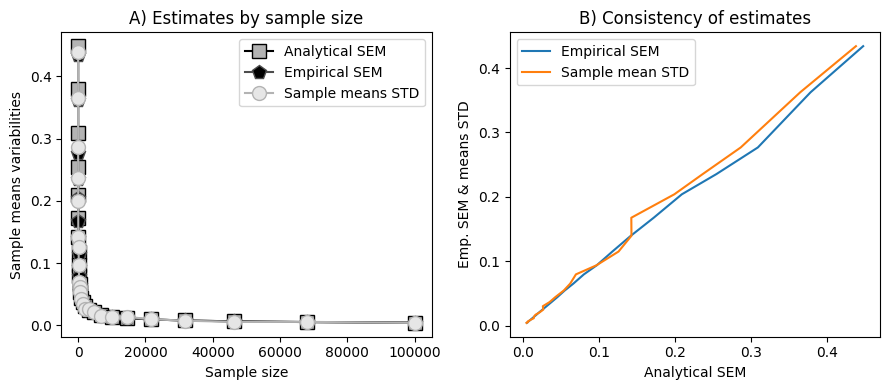

In [34]:
N_pop = 1000000
population = np.random.randn(N_pop) ** 2

sample_sizes = np.logspace(np.log10(10), np.log10(N_pop / 10), 25, dtype=int)
num_exps = 50

# theoretical standard error based on population standard deviation
theory = np.std(population) / np.sqrt(sample_sizes)

# initialize the empirical estimates
stand_error = np.zeros((num_exps, len(sample_sizes)))
sample_means = np.zeros((num_exps, len(sample_sizes)))

# Run the experiment!
for expi in range(num_exps):
    for idx, ssize in enumerate(sample_sizes):
        # generate a random sample
        rsample = np.random.choice(population, size=ssize)

        # compute its standard error (estimate) and the sample mean
        stand_error[expi, idx] = np.std(rsample, ddof=1) / np.sqrt(ssize)
        sample_means[expi, idx] = np.mean(rsample)


fig, axs = plt.subplots(1, 2, figsize=(9,4))

# ---------------- Panel A ----------------
axs[0].plot(sample_sizes, theory, 'ks-', markersize=10,
            markerfacecolor=(.7,.7,.7), label='Analytical SEM')

axs[0].plot(sample_sizes, np.mean(stand_error, axis=0), 'p-',
            color=(.3,.3,.3), markersize=10, markerfacecolor=(0,0,0),
            label='Empirical SEM')

axs[0].plot(sample_sizes, np.std(sample_means, axis=0, ddof=1), 'o-',
            color=(.7,.7,.7), markersize=10, markerfacecolor=(.9,.9,.9),
            label='Sample means STD')

axs[0].set(xlabel='Sample size', ylabel='Sample means variabilities')
axs[0].legend()
axs[0].set_title("A) Estimates by sample size")

# ---------------- Panel B ----------------
axs[1].plot(theory, np.mean(stand_error, axis=0),
            markersize=12,
            label='Empirical SEM')

axs[1].plot(np.std(sample_means, axis=0, ddof=1),
            np.mean(stand_error, axis=0),
            markersize=12,
            label='Sample mean STD')

axs[1].set(xlabel='Analytical SEM', ylabel='Emp. SEM & means STD')
axs[1].legend()
axs[1].set_title("B) Consistency of estimates")

plt.tight_layout()
plt.show()

- "Some observations: First, the variabilities of the sample means
drop precipitously as the sample size increases, which shows
that small sample sizes can be untrustworthy, but arbitrarily
large sample sizes are not increasingly beneficial. Second, the
theoretical and empirical estimates of the SEM match very
closely except for small sample sizes (the mismatches are easier
to see in panel B for larger SEMs, which come from smaller
sample sizes).

I hope this exercise clarifies the interpretation of the SEM:
It reflects the uncertainty of how accurately the sample mean
estimates the true population mean. The conclusions from
the exercises on LLN and CLT are that large sample sizes —
or multiple independent random samples — are best."